# SEM receivers · pressure, particle velocity, rotation and DAS strain

One simulation, the sensors of a marine survey: a dual-sensor streamer in the water (pressure
and vertical particle velocity), nodes on the sea floor (velocity, pressure, rotation) and a DAS
fibre along the floor (strain rate). Each receiver records at its point, from the field of the
element that holds it:

| `receiver_type` | in the water | in the rock |
|---|---|---|
| `p` | `-d2(chi)/dt2` | `-kappa div u` |
| `vx`, `vz` | `grad(chi_dot) / rho` | `du/dt` |
| `rot_y` | 0 | `curl(u) / 2` |
| `exx_t` | 0 | `d(vx)/dx`, the strain rate along x |

See [Strain, rotation and pressure](../../user-guide/sem/#strain-rotation-and-pressure).

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import AcousticElasticSEM2D, PropSEM

DEV = "cuda" if torch.cuda.is_available() else "cpu"
DH, NO = 5.0, 4                          # grid cell; elements of 4 cells = 20 m
NX, NZ = 801, 301                        # 4000 m x 1500 m
F0, T_REC = 10.0, 2.0
DT = 4e-4
NT = int(round(T_REC / DT))
WATER = dict(vp=1500.0, vs=0.0, rho=1020.0)
ROCK = dict(vp=2500.0, vs=1250.0, rho=2200.0)


def floor(x):
    """Sea-floor depth (m): 300 m, a seamount up to 200 m at x = 2600 m."""
    return 300.0 - 100.0 * np.exp(-((x - 2600.0) / 350.0) ** 2)

## 1. Model and acquisition

`interfaces` gives the sea floor, in rows for each column, and the Quad9 mesh follows it
(`interface_elements`: the element rows of each layer). All the receivers are rows of one
`receivers` array and record all five components; each group keeps the ones its sensor
measures.

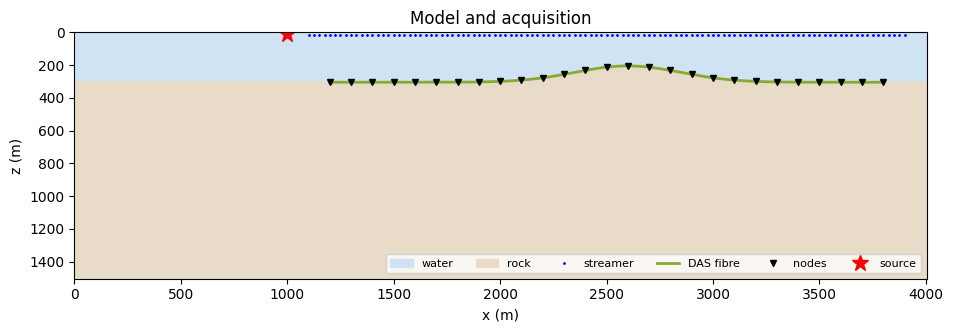

In [2]:
xg = np.arange(NX) * DH
prop = PropSEM(AcousticElasticSEM2D, shape=(NZ, NX), dh=DH, dt=DT, n_order=NO,
               interfaces=[floor(xg) / DH], interface_elements=[15, 60],
               free_surface=True, f_dominant=F0, source_type=["chi"],
               receiver_type=["p", "vx", "vz", "rot_y", "exx_t"], dev=DEV)
models = [prop.layered_model([WATER[k], ROCK[k]]) for k in ("vp", "vs", "rho")]

src = np.array([[200, 2]])                                  # airgun: x 1000 m, 10 m deep
x_str = np.arange(1100.0, 3901.0, 25.0)                     # streamer, 15 m deep
x_obn = np.arange(1200.0, 3801.0, 100.0)                    # nodes, 5 m below the floor
x_das = np.arange(1200.0, 3801.0, 10.0)                     # fibre, 5 m below the floor
groups = {"streamer": np.stack([x_str, np.full_like(x_str, 15.0)], 1),
          "nodes": np.stack([x_obn, floor(x_obn) + 5.0], 1),
          "fibre": np.stack([x_das, floor(x_das) + 5.0], 1)}
rec = np.concatenate(list(groups.values())) / DH            # metres -> grid indices
sl, lo = {}, 0
for k, v in groups.items():
    sl[k] = slice(lo, lo + len(v)); lo += len(v)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.fill_between(xg, 0, floor(xg), color="#cfe3f5", label="water")
ax.fill_between(xg, floor(xg), NZ * DH, color="#e8dcc8", label="rock")
ax.plot(*groups["streamer"].T, "b.", ms=2, label="streamer")
ax.plot(*groups["fibre"].T, "-", color="#8a3", lw=2, label="DAS fibre")
ax.plot(*groups["nodes"].T, "kv", ms=4, label="nodes")
ax.plot(src[0, 0] * DH, src[0, 1] * DH, "r*", ms=12, label="source")
ax.set_ylim(NZ * DH, 0); ax.set_xlim(0, NX * DH)
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)"); ax.legend(ncol=6, fontsize=8, loc="lower right")
ax.set_title("Model and acquisition"); plt.show()

## 2. One run

The pressure source loads the potential with the wavelet over the water's bulk modulus
(the `chi` source, SPECFEM2D's normalization).

In [3]:
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - 1.2 / F0)) ** 2
wav = torch.tensor((1.0 - 2.0 * a) * np.exp(-a) / (WATER["rho"] * WATER["vp"] ** 2),
                   dtype=torch.float32, device=DEV)
with torch.no_grad():
    seis = prop(wav, src, rec[None], models=models)[0].cpu().numpy()   # (nt, nrec, 5)
print(f"impl {prop.impl}, seismograms {seis.shape}")
P, VX, VZ, ROT, EXX_T = range(5)

impl c, seismograms (5000, 401, 5)


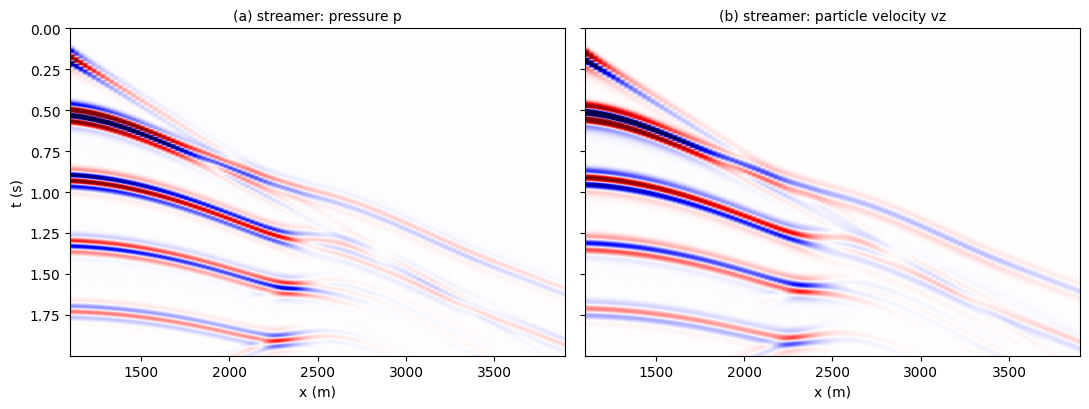

In [4]:
def gather(ax, data, x, title, clip=0.995):
    v = np.quantile(np.abs(data), clip)
    ax.imshow(data, aspect="auto", cmap="seismic", vmin=-v, vmax=v,
              extent=[x[0], x[-1], t[-1], t[0]])
    ax.set_title(title, fontsize=10); ax.set_xlabel("x (m)")


fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
gather(ax[0], seis[:, sl["streamer"], P], x_str, "(a) streamer: pressure p")
gather(ax[1], seis[:, sl["streamer"], VZ], x_str, "(b) streamer: particle velocity vz")
ax[0].set_ylabel("t (s)"); plt.tight_layout(); plt.show()

The streamer's two channels differ where the sea surface reflects: the pressure-free surface
changes the sign of the downgoing pressure but not that of the downgoing particle velocity, which
is what dual-sensor deghosting combines. In the water `vz` is the potential's gradient over the
density.

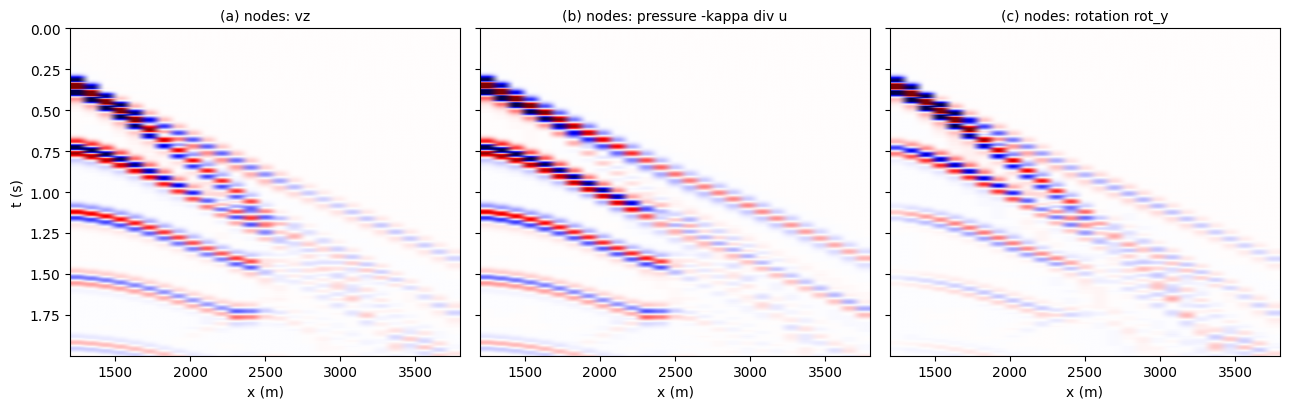

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
gather(ax[0], seis[:, sl["nodes"], VZ], x_obn, "(a) nodes: vz")
gather(ax[1], seis[:, sl["nodes"], P], x_obn, "(b) nodes: pressure -kappa div u")
gather(ax[2], seis[:, sl["nodes"], ROT], x_obn, "(c) nodes: rotation rot_y")
ax[0].set_ylabel("t (s)"); plt.tight_layout(); plt.show()

All three record the arrivals from the water column -- the direct wave and the water-layer
multiples -- as they cross the floor. The pressure takes their P part (`div u`) and the rotation
their S part (`curl u`), so the two weigh the same arrivals differently along the line.

## 3. DAS strain rate

The fibre records `exx_t = d(vx)/dx`, the strain rate along it, from the gradient of the
element's basis at each channel.

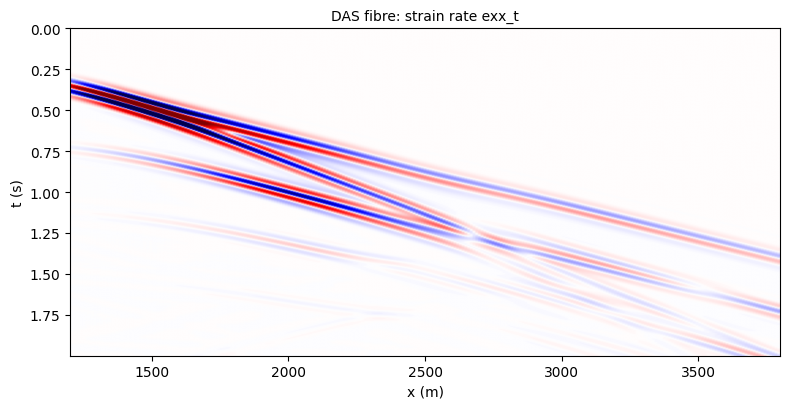

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
gather(ax, seis[:, sl["fibre"], EXX_T], x_das, "DAS fibre: strain rate exx_t")
ax.set_ylabel("t (s)"); plt.tight_layout(); plt.show()

## 4. Notes

- **Where a receiver sits.** On `AcousticElasticSEM2D` each receiver takes its element's medium:
  `vx`, `vz` and `p` are the water's in the water and the rock's in the rock, and the strain and
  rotation are zero in the water.
- **Velocity-stress classes.** Their fields are the velocity, and they record the strain as the
  running sum of the strain rate times `dt`.
- **Gradients.** The receivers are linear in the fields, so `loss.backward()` goes through them
  on both backends.

---

<p><strong>Download this notebook</strong> &mdash; <a href="47_sem_receivers.ipynb" download><code>47_sem_receivers.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/47_sem_receivers.ipynb">view on GitHub</a></p>